**Step 1: Import Libraries**

In [115]:
# data handling
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#spliting
from sklearn.model_selection import train_test_split

# preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight # bonus

# deep learning core
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model # Required instead of Sequential for multi-output networks
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, ReLU
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
import keras_tuner as kt
#import shap

# model evaluation
from sklearn.metrics import classification_report, roc_auc_score   # For Attrition (Classification)
from sklearn.metrics import confusion_matrix                       # For Monthly Income (Regression)

**Step 2: Load Data**

In [98]:
df = pd.read_csv("../data/employee_clean.csv")

**Step 3: Features & Target**

In [99]:
X = df.drop(columns=['EmployeeNumber','Attrition','MonthlyIncome'])
y = df['Attrition']

**Step 4: Train Test Split**

In [100]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Step 5: Preprocessing pipeline**

**1. Encode Target**

In [101]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

**2. Encode Features**

In [102]:
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
num_cols = numerical_features = [
    'Age', 'DailyRate', 'DistanceFromHome', 'Education', 'HourlyRate', 
    'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'EnvironmentSatisfaction',
    'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 
    'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 
    'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
]

num_transformer = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scr", StandardScaler())
])

cat_transformer = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),

    # 'sparse_output=False' --> ensures it returns a normal numpy array instead of a matrix
    # 'drop='first'' --> removes one column per feature to prevent the dummy variable trap
    ('cat', OneHotEncoder(sparse_output=False, drop='first'))
])


preprocessor = ColumnTransformer([
    ("num_processing", num_transformer, num_cols),
    ("cat_processing", cat_transformer, cat_cols)
], remainder='passthrough' 
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

**Step 6: Build ANN**

In [103]:
model = Sequential([
    # input layer
    Input(shape=(X_train_processed.shape[1],)), # Add a comma after the integer to convert it into a one-dimensional tuple
    
    # hidden layer 1
    Dense(64),                                  # Removed activation to place before BatchNorm
    BatchNormalization(),                       # Batch normalization for more stable training
    tf.keras.layers.Activation('relu'),
    Dropout(0.3),                               # Dropout to reduce overfitting.
    
    # hidden layer 2
    Dense(32),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    Dropout(0.3),

    # hidden layer 3
    Dense(16),
    BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    # output layer for binary classification
    Dense(1, activation='sigmoid')
])


**Step 7: Compile**

In [105]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

**Step 8: Summary**

In [106]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,665 (22.13 KB)

 Non-trainable params: 224 (896.00 B)

**Step 9: Train**

In [107]:
# batch_size = The model processes 100 rows of data at a time.
# epochs = The model will see the whole dataset 10 times in total
# validation_data = to get testing accuracy
# callbacks = stops overfitting when occur

history = model.fit(
    X_train_processed,
    y_train_encoded,
    validation_split=0.2,
    epochs=50,
    batch_size=100,
    callbacks=EarlyStopping()
)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5319 - loss: 0.7773 - val_accuracy: 0.4153 - val_loss: 0.7489
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5606 - loss: 0.7397 - val_accuracy: 0.5339 - val_loss: 0.6943
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6415 - loss: 0.6531 - val_accuracy: 0.6525 - val_loss: 0.6505
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6681 - loss: 0.6120 - val_accuracy: 0.7161 - val_loss: 0.6239
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7202 - loss: 0.5744 - val_accuracy: 0.7500 - val_loss: 0.6066
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7553 - loss: 0.5470 - val_accuracy: 0.7839 - val_loss: 0.5918
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7766 - loss: 0.5270 - val_accuracy: 0.7924 - val_loss: 0.5765
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7947 - loss: 0.4900 - val_accuracy: 0.8008 - val_loss

**Step 10: Prediction**

In [ ]:
y_pred_probs = model.predict(X_test_processed)

#used to convert continuous probabilities into definitive class predictions
#but it only works for `binary classification (2 classes)``. It will break your `multi-class (3 classes) model``.
y_pred_classes  = (y_pred_probs > 0.5).astype(int)  # evaluates to True, , which .astype(int) turns into a class label of 1.

**Step 10: Evaluate**

In [127]:
# Evaluate the model on the test data to get final test loss and accuracy
loss, accuracy = model.evaluate(X_test_processed, y_test_encoded, verbose=0)

print(f"Test Loss:     {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss:     0.3197
Test Accuracy: 0.8844


In [126]:
# 1. Generate the raw probability predictions
y_pred_probs = model.predict(X_test_processed).flatten()

# 2. Calculate the ROC-AUC score first (Critical step)
roc_auc = roc_auc_score(y_test_encoded, y_pred_probs)

# 3. Print the calculated score second
print(f"ROC-AUC:   {roc_auc:.4f}\n")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
ROC-AUC:   0.7935



**Step 12: Classification Report**

In [110]:
print(classification_report(y_test_encoded, pred))

              precision    recall  f1-score   support

           0       0.91      0.96      0.93       255
           1       0.59      0.41      0.48        39

    accuracy                           0.88       294
   macro avg       0.75      0.68      0.71       294
weighted avg       0.87      0.88      0.88       294



**Step 13: Confusion Matrix**

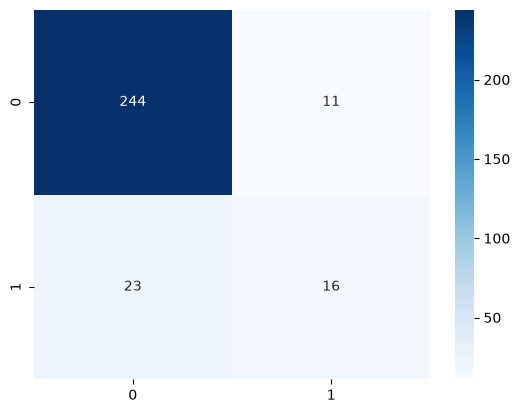

In [111]:
cm = confusion_matrix(y_test_encoded, pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.show()

**Step 14: Training Curves**

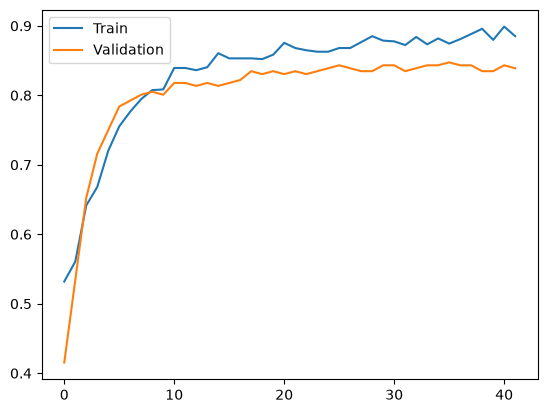

In [112]:
# here only accuracy / loss curve

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Validation'])
plt.show()

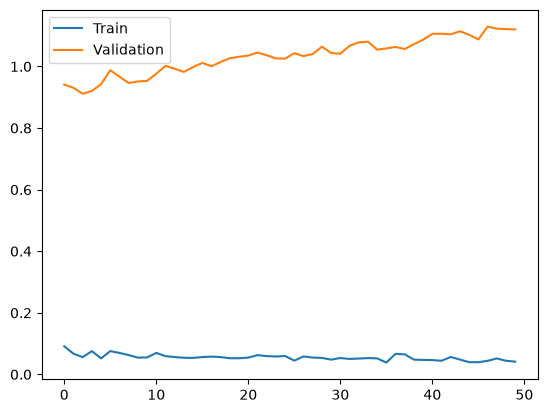

In [73]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.show()

**Step 15: Save Model**

In [113]:
model.save("../Models/attrition_model.keras")
print("Model Saved successfully...!")

Model Saved successfully...!
